# 04 · Retrieving spatial data and understanding sources

Lecture 3 · English teaching notebook.

We explore how to find, download, interpret and compare geographic data. Each step produces an object, table or map to inspect before continuing.

1. Discover data collections and request geographic features.
2. Read the pharmacy CSV and investigate its coordinates.
3. Compare geocoding services using the original city and address examples.
4. Retrieve OSM pharmacies and compare the observations on a HOT OSM map.

Run cells in order. All variables are defined here. The `data` folder stores downloaded responses. The support function reuses those files; it does not silently refresh an existing snapshot. The geocoding section is a small live instructor demonstration, not a simultaneous class-wide exercise.

## Setup

**Learning objective:** Prepare a Colab environment without modifying system packages.

**Colab AI prompt:**

> Install GeoPandas, requests, geopy, matplotlib and folium for a Colab notebook. Avoid --break-system-packages.

**Check after execution:** Restart the runtime only if Colab reports an import conflict.

In [1]:
%pip install -q "geopandas>=1.2,<2" "pandas>=2.2,<4" "requests>=2.32" "geopy>=2.4,<3" "matplotlib>=3.10,<4" "folium>=0.20,<1" "mapclassify>=2.8,<3"

In [2]:
# All imports used in later cells are declared here.
from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import urljoin
import json
import hashlib
import platform
import importlib.metadata
import time
import xml.etree.ElementTree as ET
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display
from shapely.geometry import Point, box


## Configuration and technical support

`DATA` is the folder for source files. `STUDY_BBOX` is the central Trento rectangle, written as west, south, east, north. It is not the municipal boundary.

We use **ASUIT** as the classroom label for the health-service observations. The chosen source is still served at the `apss.tn.it` URL; source metadata and historical names are kept as published.

The download helper below records the URL, retrieval time and file hash. Run it once. Its internals are supporting material; the following examples print their requests and show their responses explicitly.

In [3]:
# Directory for source files; generated outputs use separate filenames.
DATA = Path("data")
DATA.mkdir(exist_ok=True)
# Teaching snapshot label, not the dataset reference date or actual download time.
RETRIEVAL_SNAPSHOT_LABEL = pd.Timestamp("2026-10-29")
# Central Trento study window. The slide's Overpass example uses a wider rectangle.
STUDY_BBOX = (11.095, 46.045, 11.145, 46.085)  # west, south, east, north
STUDY_AREA = gpd.GeoSeries([box(*STUDY_BBOX)], crs=4326)
PHARMACY_URL = "https://servizi.apss.tn.it/opendata/FARM001.csv"
PHARMACY_CATALOGUE = "https://dati.trentino.it/it/dataset/farmacie-pat"
USER_AGENT = "unitn-geospatial-lecture3/2026 (educational; mailto:napolitano@fbk.eu)"
# The manifest records request URLs, actual retrieval times and content hashes.
manifest_path = DATA / "source_manifest.json"
manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
versions = {
    name: importlib.metadata.version(name)
    for name in ["geopandas", "pandas", "requests"]
}


In [4]:
def cached_get(url, filename, params=None):
    # Define the local path for the file inside the data directory
    path = DATA / filename

    # Show the exact request so the source and parameters remain visible.
    print("Request:", requests.Request("GET", url, params=params).prepare().url)

    # Normalize and prepare the URL with any query parameters to use as a cache key
    prepared_url = requests.Request("GET", url, params=params).prepare().url

    # If the file already exists locally but its registered URL in the manifest differs from the requested one,
    # raise an error to prevent cache collisions or serving incorrect datasets
    if (
        path.exists()
        and filename in manifest
        and manifest[filename].get(
            "url", manifest[filename].get("expected_request_url")
        )
        not in (None, prepared_url)
    ):
        raise ValueError(
            f"Cache query differs for {filename}; choose another filename or review the cache."
        )

    # If the file is not found locally, proceed with downloading it (Cache Miss)
    if not path.exists():
        # Execute the HTTP GET request with a 60-second timeout and a specific User-Agent
        response = requests.get(
            url, params=params, headers={"User-Agent": USER_AGENT}, timeout=60
        )
        response.raise_for_status()  # Raise an exception if the HTTP request failed

        # Save the downloaded binary content to the local file path
        path.write_bytes(response.content)

        # Record download metadata in the manifest (URL, UTC retrieval timestamp, Content-Type, and SHA-256 hash)
        manifest[filename] = {
            "url": prepared_url,
            "retrieved_utc": datetime.now(timezone.utc).isoformat(),
            "content_type": response.headers.get("Content-Type"),
            "last_modified": response.headers.get("Last-Modified"),
            "sha256": hashlib.sha256(response.content).hexdigest(),
        }
        # Update the manifest JSON file on disk
        manifest_path.write_text(json.dumps(manifest, indent=2))

    # If the file exists on disk but has no entry in the manifest (e.g., manually placed files)
    elif filename not in manifest:
        # Register the file in the manifest, compute its SHA-256, and add a provenance disclaimer
        manifest[filename] = {
            "url": None,
            "expected_request_url": prepared_url,
            "retrieved_utc": None,
            "provenance_note": "Local file supplied without retrieval metadata; verify origin.",
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        }
        # Save the updated manifest to disk
        manifest_path.write_text(json.dumps(manifest, indent=2))

    # Validate local file integrity by comparing its current SHA-256 hash with the manifest record
    if hashlib.sha256(path.read_bytes()).hexdigest() != manifest[filename]["sha256"]:
        raise ValueError(f"Cached file changed: {filename}")

    # Return the verified local Path object
    return path


In [5]:
print("Python:", platform.python_version(), "Packages:", versions)
print(
    "Study bbox:",
    STUDY_BBOX,
    "Pharmacy retrieval snapshot label:",
    RETRIEVAL_SNAPSHOT_LABEL.date(),
)


Python: 3.13.18 Packages: {'geopandas': '1.2.0', 'pandas': '2.2.3', 'requests': '2.32.4'}
Study bbox: (11.095, 46.045, 11.145, 46.085) Pharmacy retrieval snapshot label: 2026-10-29


### Source, format and access method

| Question | Example | Evidence to inspect |
|---|---|---|
| Who publishes it? | APSS, ISTAT, OSM contributors | Publisher and documentation |
| How is it encoded? | CSV, GeoJSON, GeoPackage, OSM PBF | Schema, format and CRS |
| How do we request it? | HTTP download, WFS, OGC API Features, Overpass | Endpoint, parameters, limits and response |

Start with [RNDT](https://geodati.gov.it/geoportale/eng/catalogo), [OGC standards](https://www.ogc.org/standards/) and the [APSS dataset catalogue](https://dati.trentino.it/it/dataset/farmacie-pat). The catalogue describes the dataset; the CSV contains observations. A public download URL does not establish a licence by itself.

## A source assessment table

**Learning objective:** Record what is known and what remains missing.

**Colab AI prompt:**

> Create an editable source assessment table with publisher, URL, reference date, licence evidence, intended use and unresolved questions. Do not invent a licence.

**Check after execution:** Fill the licence fields after opening the linked source documentation.

In [6]:
source_assessment = pd.DataFrame(
    [
        {
            "dataset": "APSS pharmacy dataset",
            "publisher": "APSS Trentino",
            "url": PHARMACY_CATALOGUE,
            "retrieval_snapshot_label": str(RETRIEVAL_SNAPSHOT_LABEL.date()),
            "licence_evidence": "Not established by the CSV alone: inspect APSS dataset metadata before redistribution",
            "intended_use": "Pharmacy identity and observed coordinates",
        },
        {
            "dataset": "OpenStreetMap",
            "publisher": "OSM contributors",
            "url": "https://www.openstreetmap.org/copyright",
            "reference_date": "Record retrieval snapshot",
            "licence_evidence": "ODbL, attribution required",
            "intended_use": "Street network and contextual POIs",
        },
        {
            "dataset": "OGC API demonstration",
            "publisher": "pygeoapi demo / underlying data publisher",
            "url": "https://demo.pygeoapi.io/master/collections",
            "reference_date": "Inspect collection metadata",
            "licence_evidence": "Inspect collection and original source",
            "intended_use": "Learn the access protocol; not Trento pharmacy analysis",
        },
    ]
)
display(source_assessment)


,dataset,publisher,url,retrieval_snapshot_label,licence_evidence,intended_use,reference_date
0,APSS pharmacy dataset,APSS Trentino,https://dati.trentino.it/it/dataset/farmacie-pat,2026-10-29,Not established by the CSV alone: inspect APSS...,Pharmacy identity and observed coordinates,NaN
1,OpenStreetMap,OSM contributors,https://www.openstreetmap.org/copyright,NaN,"ODbL, attribution required",Street network and contextual POIs,Record retrieval snapshot
2,OGC API demonstration,pygeoapi demo / underlying data publisher,https://demo.pygeoapi.io/master/collections,NaN,Inspect collection and original source,Learn the access protocol; not Trento pharmacy...,Inspect collection metadata


## OGC API: discover what the server offers

### Ask for the collection list

A collection description contains metadata, not the features themselves.

**AI prompt:** Request the pygeoapi collections as JSON. Print its top-level keys and the number of advertised collections.

**Look at the result:** Which key contains the collection descriptions?

In [7]:
API = "https://demo.pygeoapi.io/master"
collections_file = cached_get(
    API + "/collections", "ogc_collections.json", {"f": "json"}
)
collections = json.loads(collections_file.read_text())
print("Response keys:", list(collections))
print("Advertised collections:", len(collections["collections"]))


Request: https://demo.pygeoapi.io/master/collections?f=json
Response keys: ['collections', 'links']
Advertised collections: 17


### Inspect one description, then summarise

See the structure before extracting fields.

**AI prompt:** Show one collection description. Then create collections_table with id and title, using a readable loop.

**Look at the result:** How does each table row relate to the JSON?

In [8]:
display(collections["collections"][0])
collection_rows = []
for collection in collections["collections"]:
    collection_rows.append({"id": collection["id"], "title": collection.get("title")})
collections_table = pd.DataFrame(collection_rows)
display(collections_table)


{'id': 'obs',
 'links': [{'type': 'text/csv',
   'rel': 'canonical',
   'title': 'data',
   'href': 'https://github.com/mapserver/mapserver/blob/branch-7-0/msautotest/wxs/data/obs.csv',
   'hreflang': 'en-US'},
  {'type': 'text/csv',
   'rel': 'alternate',
   'title': 'data',
   'href': 'https://raw.githubusercontent.com/mapserver/mapserver/branch-7-0/msautotest/wxs/data/obs.csv',
   'hreflang': 'en-US'},
  {'type': 'application/json',
   'rel': 'root',
   'title': 'The landing page of this server as JSON',
   'href': 'https://demo.pygeoapi.io/master?f=json'},
  {'type': 'text/html',
   'rel': 'root',
   'title': 'The landing page of this server as HTML',
   'href': 'https://demo.pygeoapi.io/master?f=html'},
  {'type': 'application/json',
   'rel': 'self',
   'title': 'This document as JSON',
   'href': 'https://demo.pygeoapi.io/master/collections/obs?f=json'},
  {'type': 'application/ld+json',
   'rel': 'alternate',
   'title': 'This document as RDF (JSON-LD)',
   'href': 'https://dem

,id,title
0,obs,Observations
1,lakes,Large Lakes
2,dutch_windmills,Windmills within The Netherlands
3,dutch_castles,Castles within The Netherlands
4,dutch_georef_stations,Dutch Georef Stations via OGR WFS
5,utah_city_locations,Cities in Utah via OGR WFS
6,unesco_pois_italy,Unesco POIs in Italy via OGR WFS
7,ogr_gpkg_poi,Portuguese Points of Interest via OGR GPKG
8,ogr_geojson_lakes,Large Lakes OGR GeoJSON Driver
9,ogr_gpkg_wales_railway_lines,Railway lines in Wales (UK) via OGR GPKG


### Choose the UNESCO collection

Select a collection actually advertised by the server.

**AI prompt:** Select unesco_pois_italy from collections. Show its description and source links.

**Look at the result:** Its name alone does not establish currency or completeness.

In [9]:
collection_id = "unesco_pois_italy"
selected_collection = None
for collection in collections["collections"]:
    if collection["id"] == collection_id:
        selected_collection = collection
if selected_collection is None:
    raise ValueError("Collection not advertised: inspect collections_table.")
display(selected_collection)


{'id': 'unesco_pois_italy',
 'links': [{'type': 'text/html',
   'rel': 'canonical',
   'title': 'information',
   'href': 'https://mapstore.geosolutionsgroup.com/mapstore/#',
   'hreflang': 'en-US'},
  {'type': 'application/json',
   'rel': 'root',
   'title': 'The landing page of this server as JSON',
   'href': 'https://demo.pygeoapi.io/master?f=json'},
  {'type': 'text/html',
   'rel': 'root',
   'title': 'The landing page of this server as HTML',
   'href': 'https://demo.pygeoapi.io/master?f=html'},
  {'type': 'application/json',
   'rel': 'self',
   'title': 'This document as JSON',
   'href': 'https://demo.pygeoapi.io/master/collections/unesco_pois_italy?f=json'},
  {'type': 'application/ld+json',
   'rel': 'alternate',
   'title': 'This document as RDF (JSON-LD)',
   'href': 'https://demo.pygeoapi.io/master/collections/unesco_pois_italy?f=jsonld'},
  {'type': 'text/html',
   'rel': 'alternate',
   'title': 'This document as HTML',
   'href': 'https://demo.pygeoapi.io/master/coll

### Request a first page

Use a rectangle in northern Italy; it is not a Trentino administrative boundary.

**AI prompt:** Request the selected collection with bbox 10.5,45.5,12.0,46.5 and limit=100. Inspect the response keys and one complete feature.

**Look at the result:** The bbox order is west, south, east, north. What are properties and geometry?

In [10]:
items_url = API + f"/collections/{collection_id}/items"
items_params = {"f": "json", "bbox": "10.5,45.5,12.0,46.5", "limit": 100}
request_url = requests.Request("GET", items_url, params=items_params).prepare().url
page_key = hashlib.sha256(request_url.encode()).hexdigest()[:12]
items_file = cached_get(items_url, f"ogc_unesco_{page_key}.json", items_params)
items_payload = json.loads(items_file.read_text())
if items_payload.get("type") != "FeatureCollection":
    raise ValueError("Inspect the saved response: expected a FeatureCollection.")
features = list(items_payload["features"])
print("Response keys:", list(items_payload))
print("Features in this page:", len(features))
if features:
    display(features[0])


Request: https://demo.pygeoapi.io/master/collections/unesco_pois_italy/items?f=json&bbox=10.5%2C45.5%2C12.0%2C46.5&limit=100
Response keys: ['type', 'features', 'links', 'timeStamp']
Features in this page: 10


{'type': 'Feature',
 'geometry': {'type': 'Point',
  'coordinates': [10.558013487255593, 45.535578481864356]},
 'properties': {'cod_unesco': 'IT_1363',
  'sito': "Siti palafitticoli preistorici dell'arco alpino",
  'seriale': 1,
  'cod_compon': '1363-093',
  'componente': 'San Sivino, Gabbiano\xa0',
  'tipo_area': 'sito'},
 'id': 'Unesco_point.145'}

### View the first page

Turn the returned objects into a geographic table before handling more pages.

**AI prompt:** Create a GeoDataFrame from features, preserve source feature IDs and map the first page on OpenStreetMap.HOT.

**Look at the result:** This map currently shows only the first page, not necessarily every matching object.

In [11]:
if features:
    first_page_pois = gpd.GeoDataFrame.from_features(features, crs=4326)
    first_page_pois["source_feature_id"] = [feature.get("id") for feature in features]
    display(first_page_pois.head())
    display(first_page_pois.explore(tiles="OpenStreetMap.HOT", color="blue"))
else:
    print("No features returned for this rectangle.")


,geometry,cod_unesco,sito,seriale,cod_compon,componente,tipo_area,source_feature_id
0,POINT (10.55801 45.53558),IT_1363,Siti palafitticoli preistorici dell'arco alpino,1,1363-093,"San Sivino, Gabbiano",sito,Unesco_point.145
1,POINT (11.54497 45.54901),IT_712bis,Vicenza e le Ville del Palladio nel Veneto,1,712bis-001,Città di Vicenza,sito,Unesco_point.15
2,POINT (10.7654 45.87439),IT_1363,Siti palafitticoli preistorici dell'arco alpino,1,1363-104,Molina di Ledro,sito,Unesco_point.156
3,POINT (10.8317 45.99027),IT_1363,Siti palafitticoli preistorici dell'arco alpino,1,1363-105,Fiavé-Lago Carera,sito,Unesco_point.157
4,POINT (11.54891 45.56609),IT_712bis,Vicenza e le Ville del Palladio nel Veneto,1,712bis-002,Villa Trissino Trettenero,sito,Unesco_point.16


### Does the response have another page?

Inspect pagination links before automating them.

**AI prompt:** Print the links in items_payload and collect JSON links whose rel is next into next_links.

**Look at the result:** A limit controls page size; it does not establish completeness.

In [12]:
next_links = []
for link in items_payload.get("links", []):
    print(link.get("rel"), link.get("type"), link.get("href"))
    if link.get("rel") == "next" and "json" in link.get("type", "json"):
        next_links.append(link["href"])
print("Next-page links:", next_links)


self application/geo+json https://demo.pygeoapi.io/master/collections/unesco_pois_italy/items?f=json&bbox=10.5,45.5,12.0,46.5&limit=100
alternate application/ld+json https://demo.pygeoapi.io/master/collections/unesco_pois_italy/items?f=jsonld&bbox=10.5,45.5,12.0,46.5&limit=100
alternate text/html https://demo.pygeoapi.io/master/collections/unesco_pois_italy/items?f=html&bbox=10.5,45.5,12.0,46.5&limit=100
alternate text/csv; charset=utf-8 https://demo.pygeoapi.io/master/collections/unesco_pois_italy/items?f=csv&bbox=10.5,45.5,12.0,46.5&limit=100
next application/geo+json https://demo.pygeoapi.io/master/collections/unesco_pois_italy/items?f=json&offset=10&bbox=10.5,45.5,12.0,46.5&limit=100
collection application/json https://demo.pygeoapi.io/master/collections/unesco_pois_italy
Next-page links: ['https://demo.pygeoapi.io/master/collections/unesco_pois_italy/items?f=json&offset=10&bbox=10.5,45.5,12.0,46.5&limit=100']


### Follow remaining pages

Now repeat the operation we have inspected. Keep a bounded loop and reject incomplete retrieval.

**AI prompt:** Follow next_links with a maximum of ten pages in total. Preserve features from the first page and detect repeated URLs.

**Look at the result:** If another page still exists after the limit, stop rather than claiming a complete download.

In [13]:
visited_pages = {request_url}
for page_number in range(2, 11):
    if not next_links:
        break
    items_url = urljoin(request_url, next_links[0])
    request_url = items_url
    if request_url in visited_pages:
        raise RuntimeError("Repeated next-page link.")
    visited_pages.add(request_url)
    page_key = hashlib.sha256(request_url.encode()).hexdigest()[:12]
    items_file = cached_get(items_url, f"ogc_unesco_{page_key}.json")
    items_payload = json.loads(items_file.read_text())
    if items_payload.get("type") != "FeatureCollection":
        raise ValueError("Inspect the next-page response.")
    features.extend(items_payload["features"])
    print("Page", page_number, "features:", len(items_payload["features"]))
    next_links = []
    for link in items_payload.get("links", []):
        if link.get("rel") == "next" and "json" in link.get("type", "json"):
            next_links.append(link["href"])
if next_links:
    raise RuntimeError("Download incomplete after ten pages.")
if features:
    trentino_pois = gpd.GeoDataFrame.from_features(features, crs=4326)
    trentino_pois["source_feature_id"] = [feature.get("id") for feature in features]
    print("Total features:", len(trentino_pois))
    display(trentino_pois.head())
    display(trentino_pois.explore(tiles="OpenStreetMap.HOT", color="blue"))
else:
    trentino_pois = gpd.GeoDataFrame({"geometry": []}, geometry="geometry", crs=4326)
    print(
        "No matching observations returned; this is not evidence of absence in reality."
    )


Request: https://demo.pygeoapi.io/master/collections/unesco_pois_italy/items?f=json&offset=10&bbox=10.5,45.5,12.0,46.5&limit=100
Page 2 features: 10
Request: https://demo.pygeoapi.io/master/collections/unesco_pois_italy/items?f=json&offset=20&bbox=10.5,45.5,12.0,46.5&limit=100
Page 3 features: 1
Total features: 21


,geometry,cod_unesco,sito,seriale,cod_compon,componente,tipo_area,source_feature_id
0,POINT (10.55801 45.53558),IT_1363,Siti palafitticoli preistorici dell'arco alpino,1,1363-093,"San Sivino, Gabbiano",sito,Unesco_point.145
1,POINT (11.54497 45.54901),IT_712bis,Vicenza e le Ville del Palladio nel Veneto,1,712bis-001,Città di Vicenza,sito,Unesco_point.15
2,POINT (10.7654 45.87439),IT_1363,Siti palafitticoli preistorici dell'arco alpino,1,1363-104,Molina di Ledro,sito,Unesco_point.156
3,POINT (10.8317 45.99027),IT_1363,Siti palafitticoli preistorici dell'arco alpino,1,1363-105,Fiavé-Lago Carera,sito,Unesco_point.157
4,POINT (11.54891 45.56609),IT_712bis,Vicenza e le Ville del Palladio nel Veneto,1,712bis-002,Villa Trissino Trettenero,sito,Unesco_point.16


## WFS: inspect capabilities


**Learning objective:** Read supported operations and layers before constructing requests.

**Colab AI prompt:**

> Fetch the public demo WFS GetCapabilities XML, inspect its root, operations and feature type names. Do not apply an unconditional coordinate swap.

**Check after execution:** A successful HTTP status can still carry an OGC exception; inspect the document root.

In [14]:
wfs_xml = cached_get(
    "https://demo.mapserver.org/cgi-bin/wfs",
    "wfs_capabilities.xml",
    {"service": "WFS", "version": "2.0.0", "request": "GetCapabilities"},
)
root = ET.fromstring(wfs_xml.read_bytes())
print("Root element:", root.tag)
if "Exception" in root.tag:
    raise RuntimeError(ET.tostring(root, encoding="unicode"))


Request: https://demo.mapserver.org/cgi-bin/wfs?service=WFS&version=2.0.0&request=GetCapabilities
Root element: {http://www.opengis.net/wfs/2.0}WFS_Capabilities


### Find operations and layers in the XML

Namespaced XML elements describe what can be requested.

**AI prompt:** Use explicit loops to list WFS operations and feature type names. Show one complete FeatureType XML element.

**Look at the result:** A layer description is not a downloaded geographic feature.

In [15]:
operations = []
layers = []
first_feature_type = None
for element in root.iter():
    local_name = element.tag.split("}")[-1]
    if local_name == "Operation" and "name" in element.attrib:
        operations.append(element.attrib["name"])
    if local_name == "FeatureType":
        if first_feature_type is None:
            first_feature_type = element
        for child in element:
            if child.tag.split("}")[-1] == "Name":
                layers.append(child.text)
print("Operations:", operations)
print("Layers:", layers)
if first_feature_type is not None:
    print(ET.tostring(first_feature_type, encoding="unicode"))


Operations: ['GetCapabilities', 'DescribeFeatureType', 'GetFeature', 'GetPropertyValue', 'ListStoredQueries', 'DescribeStoredQueries']
Layers: ['ms:continents', 'ms:cities']
<ns0:FeatureType xmlns:ns0="http://www.opengis.net/wfs/2.0" xmlns:ns1="http://www.opengis.net/ows/1.1" xmlns:ns2="http://www.w3.org/1999/xlink">
      <ns0:Name>ms:continents</ns0:Name>
      <ns0:Title>World continents</ns0:Title>
      <ns0:Abstract>Setup by GatewayGeo</ns0:Abstract>
      <ns0:DefaultCRS>urn:ogc:def:crs:EPSG::4326</ns0:DefaultCRS>
      <ns0:OtherCRS>urn:ogc:def:crs:EPSG::4269</ns0:OtherCRS>
      <ns0:OtherCRS>urn:ogc:def:crs:EPSG::3978</ns0:OtherCRS>
      <ns0:OtherCRS>urn:ogc:def:crs:EPSG::3857</ns0:OtherCRS>
      <ns0:OutputFormats>
        <ns0:Format>application/gml+xml; version=3.2</ns0:Format>
        <ns0:Format>text/xml; subtype=gml/3.2.1</ns0:Format>
        <ns0:Format>text/xml; subtype=gml/3.1.1</ns0:Format>
        <ns0:Format>text/xml; subtype=gml/2.1.2</ns0:Format>
        <ns0

### Download city objects

Request city features inside a rectangle covering Italy.

**AI prompt:** Use GetFeature for ms:cities with CRS84 bbox 6,35,19,48 and count=100. Save the GeoJSON and inspect its attributes and CRS.

**Look at the result:** A rectangle also includes neighbouring countries. One hundred results may be a capped sample, not the complete dataset.

In [16]:
# Download city features inside a rectangle covering Italy.
wfs_url = "https://demo.mapserver.org/cgi-bin/wfs"

# CRS84 explicitly means longitude, latitude.
# This avoids ambiguity about axis order in WFS requests.
wfs_params = {
    "service": "WFS",
    "version": "2.0.0",
    "request": "GetFeature",
    "typeNames": "ms:cities",
    "outputFormat": "application/json; subtype=geojson",
    "bbox": "6,35,19,48,urn:ogc:def:crs:OGC:1.3:CRS84",
    "count": 100,
}

# Inspect the exact request before downloading.
download_url = requests.Request("GET", wfs_url, params=wfs_params).prepare().url
print("Request URL:", download_url)

# Preserve the original GeoJSON response.
wfs_file = cached_get(
    wfs_url,
    "wfs_cities_italy_bbox_sample.geojson",
    wfs_params,
)
print("Downloaded file:", wfs_file.resolve())

# Inspect attributes, geometries and coordinate reference system.
wfs_cities = gpd.read_file(wfs_file)
print("Returned features:", len(wfs_cities))
print("CRS:", wfs_cities.crs)
display(wfs_cities.head())


Request URL: https://demo.mapserver.org/cgi-bin/wfs?service=WFS&version=2.0.0&request=GetFeature&typeNames=ms%3Acities&outputFormat=application%2Fjson%3B+subtype%3Dgeojson&bbox=6%2C35%2C19%2C48%2Curn%3Aogc%3Adef%3Acrs%3AOGC%3A1.3%3ACRS84&count=100
Request: https://demo.mapserver.org/cgi-bin/wfs?service=WFS&version=2.0.0&request=GetFeature&typeNames=ms%3Acities&outputFormat=application%2Fjson%3B+subtype%3Dgeojson&bbox=6%2C35%2C19%2C48%2Curn%3Aogc%3Adef%3Acrs%3AOGC%3A1.3%3ACRS84&count=100
Downloaded file: /content/data/wfs_cities_italy_bbox_sample.geojson
Returned features: 100
CRS: EPSG:4326


,POPULATION,NAME,geometry
0,2455596,Rome,POINT (12.48333 41.9)
1,1180683,Milan,POINT (9.2 45.46667)
2,991698,Naples,POINT (14.25 40.83333)
3,855976,Torino,POINT (7.66667 45.05)
4,699693,Tunis,POINT (10.17972 36.80278)


### Inspect the downloaded sample on a map

View names and locations rather than inferring the country from the bbox.

**AI prompt:** Map wfs_cities on OpenStreetMap.HOT using NAME as tooltip.

**Look at the result:** Can you find cities outside Italy? Why does the request include them?

In [17]:
if not wfs_cities.empty:
    display(
        wfs_cities.explore(tiles="OpenStreetMap.HOT", color="blue", tooltip=["NAME"])
    )
else:
    print("No features returned: inspect the request and saved response.")


## Pharmacy observations: inspect before transforming

## APSS source date and metadata

Original source: https://servizi.apss.tn.it/opendata/FARM001.csv

Dataset record: https://dati.trentino.it/it/dataset/farmacie-pat

The server reports **Last-Modified: 30 December 2021** for the downloaded CSV. **29 October 2026 is the retrieval snapshot date, not evidence that the observations were updated in 2026.** The catalogue describes active pharmacies, but the CSV does not provide a validity-end field to reproduce an active-at-date selection.

The catalogue labels the dataset **CC BY 4.0** and its description credits upstream Ministry of Health data under IODL 2.0. Keep both provenance statements and verify their applicability before further redistribution. Attribution: APSS / the publisher shown in the catalogue; upstream source credited in the catalogue. OSM observations and network: © OpenStreetMap contributors, ODbL.

This version uses APSS COD_FARMACIA_OD as the source ID and retains COD_FARMACIA as a separate register code. Numeric P/V agreement does not verify the actual location. The literal column names are preserved in the raw table.


### Read the original CSV

Start with the source columns and values as published.

**AI prompt:** Read FARM001.csv as strings into pharmacies_raw. Show its size, column names and first rows.

**Look at the result:** Which columns identify pharmacies, addresses and coordinate representations?

In [18]:
source_csv = cached_get(PHARMACY_URL, "FARM001.csv")
source_hash = hashlib.sha256(source_csv.read_bytes()).hexdigest()
# APSS uses comma-separated quoted fields, unlike the previous ministerial CSV.
pharmacies_raw = pd.read_csv(source_csv, sep=",", dtype=str, encoding="utf-8-sig")

print("Rows and columns:", pharmacies_raw.shape)
print(pharmacies_raw.columns.tolist())
display(pharmacies_raw.head())


Request: https://servizi.apss.tn.it/opendata/FARM001.csv
Rows and columns: (181, 19)
['COD_FARMACIA_OD', 'COD_FARMACIA', 'FARMACIA', 'IVA', 'CAP', 'COD_COMUNE', 'COMUNE', 'FRAZIONE', 'COD_PROVINCIA', 'PROVINCIA', 'COD_REGIONE', 'REGIONE', 'DATA_INIZIO', 'INDIRIZZO', 'TIPOLOGIA', 'LATITUDINE_P', 'LONGITUDINE_P', 'LATITUDINE_V', 'LONGITUDINE_V']


,COD_FARMACIA_OD,COD_FARMACIA,FARMACIA,IVA,CAP,COD_COMUNE,COMUNE,FRAZIONE,COD_PROVINCIA,PROVINCIA,COD_REGIONE,REGIONE,DATA_INIZIO,INDIRIZZO,TIPOLOGIA,LATITUDINE_P,LONGITUDINE_P,LATITUDINE_V,LONGITUDINE_V
0,FAR042101004054,4054,SILVESTRI LUCIANA,00673580221,38028,022152,REVO',-,TN,TRENTO,042,PROV. AUTON. TRENTO,2005-01-01,"VIA J. A. MAFFEI, 8",ORDINARIA,46.4123540693265,11.0520541954953,"46,4123540693265","11,0520541954953"
1,FAR042101004162,4162,FARMACIA GMG S.A.S. DEI DOTTORI RAVAGNANI CHIA...,02400290223,38061,022001,ALA,-,TN,TRENTO,042,PROV. AUTON. TRENTO,2017-07-01,"VIA DELLA ROGGIA, 9",ORDINARIA,45.7590051426327,11.0026564100186,"45,7590051426327","11,0026564100186"
2,FAR042101004163,4163,FRANZELLIN VITTORIO E C. SNC,02209460225,38061,022001,ALA,-,TN,TRENTO,042,PROV. AUTON. TRENTO,2011-09-01,"VIA SEGANTINI, 1",ORDINARIA,45.7479086521251,11.0414606774668,"45,7479086521251","11,0414606774668"
3,FAR042101004164,4164,BETTINAZZI - R. & T. PHARMA SNC,02018300224,38062,022006,ARCO,-,TN,TRENTO,042,PROV. AUTON. TRENTO,2009-09-01,"VIA GALAS, 49",ORDINARIA,45.9304227931688,10.9070021739945,"45,9304227931688","10,9070021739945"
4,FAR042101004165,4165,FAMIGLIA COOPERATIVA VALLAGARINA,00106510225,38063,022007,AVIO,-,TN,TRENTO,042,PROV. AUTON. TRENTO,2005-01-01,"PIAZZA ROMA, 6",ORDINARIA,45.7321595956525,10.9198632803229,"45,7321595956525","10,9198632803229"


### Inspect pharmacy identifiers

Compare the two source codes before renaming columns.

**AI prompt:** Show COD_FARMACIA_OD, COD_FARMACIA, FARMACIA, INDIRIZZO and COMUNE. Check missing or repeated source IDs.

**Look at the result:** A row identifier, a pharmacy identifier and a shared coordinate have different meanings.

In [19]:
display(
    pharmacies_raw[
        ["COD_FARMACIA_OD", "COD_FARMACIA", "FARMACIA", "INDIRIZZO", "COMUNE"]
    ].head()
)
print("Missing source IDs:", pharmacies_raw["COD_FARMACIA_OD"].isna().sum())
print("Repeated source IDs:", pharmacies_raw["COD_FARMACIA_OD"].duplicated().sum())


,COD_FARMACIA_OD,COD_FARMACIA,FARMACIA,INDIRIZZO,COMUNE
0,FAR042101004054,4054,SILVESTRI LUCIANA,"VIA J. A. MAFFEI, 8",REVO'
1,FAR042101004162,4162,FARMACIA GMG S.A.S. DEI DOTTORI RAVAGNANI CHIA...,"VIA DELLA ROGGIA, 9",ALA
2,FAR042101004163,4163,FRANZELLIN VITTORIO E C. SNC,"VIA SEGANTINI, 1",ALA
3,FAR042101004164,4164,BETTINAZZI - R. & T. PHARMA SNC,"VIA GALAS, 49",ARCO
4,FAR042101004165,4165,FAMIGLIA COOPERATIVA VALLAGARINA,"PIAZZA ROMA, 6",AVIO


Missing source IDs: 0
Repeated source IDs: 0


### Keep a working copy

Readable column names support the analysis; pharmacies_raw stays unchanged.

**AI prompt:** Check required columns, then rename selected columns into records. Keep pharmacy_id and register_code separate and retain record_id.

**Look at the result:** No coordinate is corrected. DATA_INIZIO alone cannot establish validity at an arbitrary date.

In [20]:
required = {
    "COD_FARMACIA_OD",
    "COD_FARMACIA",
    "FARMACIA",
    "COD_COMUNE",
    "COMUNE",
    "INDIRIZZO",
    "LATITUDINE_P",
    "LONGITUDINE_P",
    "LATITUDINE_V",
    "LONGITUDINE_V",
    "DATA_INIZIO",
    "COD_PROVINCIA",
}
if not required.issubset(pharmacies_raw.columns):
    raise ValueError("ASUIT schema changed: inspect source columns before proceeding.")
# Rename selected columns for analysis; pharmacies_raw preserves the original schema.
rename = {
    "COD_FARMACIA_OD": "pharmacy_id",
    "COD_FARMACIA": "register_code",
    "FARMACIA": "pharmacy_name",
    "COD_COMUNE": "municipality_code",
    "COMUNE": "municipality",
    "COD_PROVINCIA": "province_code",
    "INDIRIZZO": "address",
    "LATITUDINE_P": "latitude",
    "LONGITUDINE_P": "longitude",
}
records = pharmacies_raw.rename(columns=rename).copy()
records["record_id"] = pharmacies_raw.index
if records["pharmacy_id"].isna().any() or records["pharmacy_id"].duplicated().any():
    raise ValueError(
        "Missing or repeated source IDs: inspect before comparing pharmacies."
    )
# This file does not expose an end-of-validity field. Do not reuse the ministerial active-date filter.
records["start_date_parsed"] = pd.to_datetime(
    records.DATA_INIZIO, format="%Y-%m-%d", errors="coerce"
)
tn_records = records.copy()  # All source rows, not a fabricated active-at-date subset.

display(
    tn_records[
        ["record_id", "pharmacy_id", "register_code", "start_date_parsed"]
    ].head()
)


,record_id,pharmacy_id,register_code,start_date_parsed
0,0,FAR042101004054,4054,2005-01-01
1,1,FAR042101004162,4162,2017-07-01
2,2,FAR042101004163,4163,2011-09-01
3,3,FAR042101004164,4164,2009-09-01
4,4,FAR042101004165,4165,2005-01-01


### Look at coordinate strings

Inspect both published coordinate representations before parsing.

**AI prompt:** Show latitude, longitude, LATITUDINE_V and LONGITUDINE_V and their dtypes.

**Look at the result:** Which representation uses a decimal comma? Which rows have missing values?

In [21]:
display(tn_records[["latitude", "longitude", "LATITUDINE_V", "LONGITUDINE_V"]].head(10))
print(tn_records[["latitude", "longitude", "LATITUDINE_V", "LONGITUDINE_V"]].dtypes)


,latitude,longitude,LATITUDINE_V,LONGITUDINE_V
0,46.4123540693265,11.0520541954953,"46,4123540693265","11,0520541954953"
1,45.7590051426327,11.0026564100186,"45,7590051426327","11,0026564100186"
2,45.7479086521251,11.0414606774668,"45,7479086521251","11,0414606774668"
3,45.9304227931688,10.9070021739945,"45,9304227931688","10,9070021739945"
4,45.7321595956525,10.9198632803229,"45,7321595956525","10,9198632803229"
5,46.0153100445136,11.4345899281404,"46,0153100445136","11,4345899281404"
6,45.9345629,11.0942589,"45,9345629","11,0942589"
7,46.2908054279005,11.4621468378048,"46,2908054279005","11,4621468378048"
8,46.2719475733844,11.052403821412,"46,2719475733844","11,052403821412"
9,45.9090169713352,11.1996587694094,"45,9090169713352","11,1996587694094"


latitude         object
longitude        object
LATITUDINE_V     object
LONGITUDINE_V    object
dtype: object


### Convert and compare representations

Convert text to numbers; preserve conversion failures for inspection.

**AI prompt:** Parse the existing coordinate columns. Compare P and V numerically and show disagreements without replacing either representation.

**Look at the result:** Agreement between two representations does not verify the real location.

In [22]:
for col in ["longitude", "latitude"]:
    tn_records[col] = pd.to_numeric(
        tn_records[col].str.replace(",", ".", regex=False).replace("-", pd.NA),
        errors="coerce",
    )
# Compare the second coordinate representation without overwriting the original.
lat_v = pd.to_numeric(
    tn_records.LATITUDINE_V.str.replace(",", ".", regex=False), errors="coerce"
)
lon_v = pd.to_numeric(
    tn_records.LONGITUDINE_V.str.replace(",", ".", regex=False), errors="coerce"
)
coordinate_columns_agree = np.isclose(
    tn_records.latitude, lat_v, rtol=0, atol=1e-9, equal_nan=True
) & np.isclose(tn_records.longitude, lon_v, rtol=0, atol=1e-9, equal_nan=True)
coordinate_representation_disagreements = tn_records.loc[
    ~coordinate_columns_agree
].copy()

display(tn_records[["latitude", "longitude"]].head())
print("Representation disagreements:", len(coordinate_representation_disagreements))
display(coordinate_representation_disagreements)


,latitude,longitude
0,46.412354,11.052054
1,45.759005,11.002656
2,45.747909,11.041461
3,45.930423,10.907002
4,45.732160,10.919863


Representation disagreements: 0


,pharmacy_id,register_code,pharmacy_name,IVA,CAP,municipality_code,municipality,FRAZIONE,province_code,PROVINCIA,...,REGIONE,DATA_INIZIO,address,TIPOLOGIA,latitude,longitude,LATITUDINE_V,LONGITUDINE_V,record_id,start_date_parsed


### Separate unusable coordinates

A range check detects missing or impossible numbers, not positional accuracy.

**AI prompt:** Define coord_ok using longitude and latitude ranges. Keep unusable observations in unmapped_tn and display them.

**Look at the result:** Are these pharmacies absent, or are their coordinates unusable?

In [23]:
# Numeric ranges detect unusable values, not geographic accuracy.
coord_ok = tn_records.longitude.between(-180, 180) & tn_records.latitude.between(
    -90, 90
)
unmapped_tn = tn_records.loc[~coord_ok].copy()

print("Unmapped records:", len(unmapped_tn))
display(
    unmapped_tn[["pharmacy_id", "address", "municipality", "latitude", "longitude"]]
)


Unmapped records: 9


,pharmacy_id,address,municipality,latitude,longitude
172,FAR042101020455,"VIA MOSCHERI, 7",TRAMBILENO,NaN,NaN
173,FAR042101020775,"VIA TRENTO, 7",CLES,NaN,NaN
174,FAR042101020783,"VIA FIORINI, 37",MEZZOLOMBARDO,NaN,NaN
175,FAR042101020784,"VIA GIUSEPPE GIUSTI, 20-22",TRENTO,NaN,NaN
176,FAR042101020794,"VIA SANTA CATERINA, 80/A",ARCO,NaN,NaN
177,FAR042101020813,"VIA LAGORAI, 12",PERGINE VALSUGANA,NaN,NaN
178,FAR042101020824,"VIA ROVIGO, 25",RIVA DEL GARDA,NaN,NaN
179,FAR042101020825,"VIA MAFFEI, 3",LEDRO,NaN,NaN
180,FAR042101020872,"VIA ROMANA, 16",MEZZOCORONA,NaN,NaN


### Construct and map points

Now create geometry from the numeric coordinates.

**AI prompt:** Build tn_points using x=longitude and y=latitude in EPSG:4326. Inspect one geometry and map the observed locations with HOT OSM.

**Look at the result:** The CRS interpretation and numeric ranges alone do not establish accuracy.

In [24]:
tn_points = gpd.GeoDataFrame(
    tn_records.loc[coord_ok].copy(),
    geometry=gpd.points_from_xy(
        tn_records.loc[coord_ok, "longitude"], tn_records.loc[coord_ok, "latitude"]
    ),
    crs=4326,
)
# EPSG:4326 is an explicit interpretation of ASUIT longitude/latitude values.
# Decimal-separator agreement and numeric ranges do not verify positional accuracy.

print("CRS:", tn_points.crs)
if not tn_points.empty:
    print("First geometry:", tn_points.geometry.iloc[0])
    display(
        tn_points.explore(
            tiles="OpenStreetMap.HOT", color="green", tooltip=["pharmacy_id", "address"]
        )
    )


CRS: EPSG:4326
First geometry: POINT (11.0520541954953 46.4123540693265)


### Select the study rectangle

Filter by an explicit spatial relationship.

**AI prompt:** Create pharmacies_study from tn_points intersecting STUDY_AREA. Show the rectangle and the selected points on the same HOT map.

**Look at the result:** How many observations remain? This selects a rectangle, not a municipality.

In [25]:
pharmacies_study = tn_points.loc[tn_points.intersects(STUDY_AREA.iloc[0])].copy()
print(
    "Mapped in the source:",
    len(tn_points),
    "Inside study rectangle:",
    len(pharmacies_study),
)
display(pharmacies_study[["pharmacy_id", "address", "municipality"]].head())
study_map = STUDY_AREA.explore(
    tiles="OpenStreetMap.HOT", color="black", style_kwds={"fillOpacity": 0.03}
)
if not pharmacies_study.empty:
    pharmacies_study.explore(
        m=study_map, color="green", tooltip=["pharmacy_id", "address"]
    )
display(study_map)
assert len(tn_records) == len(tn_points) + len(unmapped_tn)


Mapped in the source: 172 Inside study rectangle: 20


,pharmacy_id,address,municipality
16,FAR042101004178,"PIAZZA DUOMO, 10",TRENTO
18,FAR042101004180,"PIAZZA PASI, 20",TRENTO
24,FAR042101004186,"LARGO MEDAGLIE D'ORO, 8",TRENTO
29,FAR042101004191,"VIA TAMBOSI, 2",TRENTO
85,FAR042101004250,"VIA ALESSANDRO MANZONI, 7/A",TRENTO


## Coincident points from the previous lesson

**Learning objective:** Separate one visible marker from several distinct entities.

**Colab AI prompt:**

> Group mapped APSS pharmacies by exact latitude and longitude. Count distinct pharmacy IDs and inspect addresses for the largest repeated location. Do not round or jitter source coordinates.

**Check after execution:** Inspect the APSS result rather than inheriting the counts from the previous ministerial source. A repeated coordinate is a review flag, not a correction.

In [26]:
# Group exact coordinates: several source IDs at one position are a review flag.
location_counts = tn_points.groupby(["latitude", "longitude"]).agg(
    rows=("record_id", "size"),
    distinct_ids=("pharmacy_id", "nunique"),
    addresses=("address", "nunique"),
)
repeated_locations = location_counts.query("distinct_ids > 1").sort_values(
    "distinct_ids", ascending=False
)
display(repeated_locations)


,,rows,distinct_ids,addresses
latitude,longitude,,,
46.062206,11.111765,7,7,7
46.061640,11.239847,4,4,4
46.069692,11.121089,3,3,3
45.856661,10.951773,2,2,2
45.891537,11.038495,2,2,2
45.884112,11.041661,2,2,2
46.151283,11.104254,2,2,2
46.323731,10.801316,2,2,2


### Read the records behind one marker

Inspect the addresses at the largest shared location before deciding what happened.

**AI prompt:** Select the coordinate pair with the largest number of distinct IDs. Display its IDs and addresses. Add coincident_ids to tn_points and refresh pharmacies_study for the later comparison.

**Look at the result:** Shared coordinates are a review flag. Keep all original records and positions.

In [27]:
if not repeated_locations.empty:
    lat, lon = repeated_locations.index[0]
    selected_group = tn_points.loc[
        tn_points.latitude.eq(lat) & tn_points.longitude.eq(lon)
    ].copy()
    display(
        selected_group[
            [
                "record_id",
                "pharmacy_id",
                "address",
                "municipality",
                "latitude",
                "longitude",
            ]
        ]
    )
    display(
        selected_group.explore(
            tiles="OpenStreetMap.HOT", color="red", tooltip=["pharmacy_id", "address"]
        )
    )
# Annotate records only after inspecting the grouped results.
tn_points["coincident_ids"] = tn_points.groupby(["latitude", "longitude"])[
    "pharmacy_id"
].transform("nunique")
pharmacies_study = tn_points.loc[tn_points.intersects(STUDY_AREA.iloc[0])].copy()


,record_id,pharmacy_id,address,municipality,latitude,longitude
18,18,FAR042101004180,"PIAZZA PASI, 20",TRENTO,46.062206,11.111765
86,86,FAR042101004251,"VIA G. MANCI, 42",TRENTO,46.062206,11.111765
98,98,FAR042101004264,"VIA HERRSCHING, 1",TRENTO,46.062206,11.111765
104,104,FAR042101004272,"LOCALITÀ SOPRAMONTE, 16",TRENTO,46.062206,11.111765
117,117,FAR042101016665,"LOC. SAN DONÀ, 50",TRENTO,46.062206,11.111765
121,121,FAR042101016677,"PIAZZALE EUROPA, 8",TRENTO,46.062206,11.111765
155,155,FAR042101018181,"P.ZZA DELL'ARGENTARIO, 10",TRENTO,46.062206,11.111765


## Geocoding: from place names to coordinates

A geocoder interprets a textual description and proposes a geographic location.

We start with city names, inspect the returned geometries and then compare
how different services interpret the same address.

GeoPandas uses geopy to access geocoding providers.
The provider supplies the results; the Python library provides the interface.

- [GeoPy documentation](https://geopy.readthedocs.io/en/stable/)
- [Compare geocoding services with getlon.lat](https://getlon.lat/)

These live examples are instructor demonstrations. Service availability,
access conditions and results can change.

In [28]:
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
from functools import lru_cache


### 1. Locate cities with ArcGIS

We provide ten city names and inspect the returned addresses and points.

Before running the cell:
- What does a point representing a city mean?
- Will the returned address contain information absent from our input?

**AI prompt:** Geocode these ten Italian city names with GeoPandas using
ArcGIS. Keep the input names beside the results and display their geometries.
Do not invent coordinates for missing results.

,city,address,geometry
0,Roma,Roma,POINT (12.49427 41.89056)
1,Palermo,Palermo,POINT (13.36147 38.11566)
2,Trento,Trento,POINT (11.11907 46.06667)
3,Genova,Genova,POINT (8.93399 44.40706)
4,Bari,Bari,POINT (16.87211 41.12591)
5,Trieste,Trieste,POINT (13.77852 45.6536)
6,Napoli,Napoli,POINT (14.25254 40.83998)
7,Cagliari,Cagliari,POINT (9.10932 39.21541)
8,Messina,Messina,POINT (15.55552 38.19233)
9,Lecce,Lecce,POINT (18.17401 40.35329)


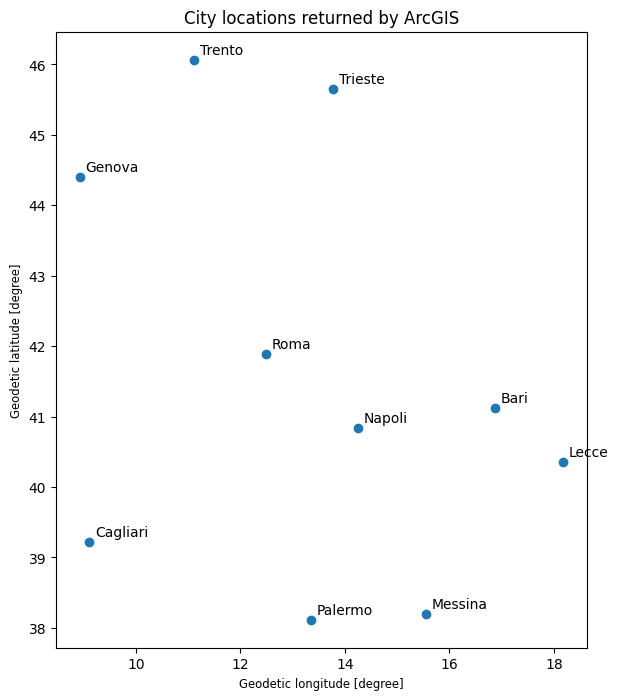

In [29]:
# Keep the original city names so we can compare input and output.
cities = pd.DataFrame(
    {
        "city": [
            "Roma",
            "Palermo",
            "Trento",
            "Genova",
            "Bari",
            "Trieste",
            "Napoli",
            "Cagliari",
            "Messina",
            "Lecce",
        ]
    }
)

# The service returns a proposed location and a formatted address.
geo_cities = gpd.tools.geocode(
    cities["city"],
    provider="arcgis",
    timeout=20,
)

geo_cities["city"] = cities["city"]
display(geo_cities[["city", "address", "geometry"]])

# Missing results remain visible in the table.
valid_cities = geo_cities.loc[
    geo_cities.geometry.notna() & ~geo_cities.geometry.is_empty
]

if not valid_cities.empty:
    ax = valid_cities.plot(figsize=(8, 8))

    for _, city in valid_cities.iterrows():
        ax.annotate(
            city["city"],
            (city.geometry.x, city.geometry.y),
            xytext=(4, 4),
            textcoords="offset points",
        )

    ax.set_title("City locations returned by ArcGIS")
    plt.show()


### 2. Read a point's coordinates

Select the result for Trento and inspect its geometry.

In a Shapely point:
- x is the first coordinate;
- y is the second coordinate.

For these longitude/latitude data, x is longitude and y is latitude.
The CRS tells us how to interpret the numbers.

**AI prompt:** Select Trento from geo_cities. Show its CRS, WKT, x and y.
Explain what the coordinates represent without calculating distances in degrees.

In [30]:
# Select by the input name, rather than relying on a row position.
trento_point = geo_cities.loc[geo_cities["city"].eq("Trento"), "geometry"].iloc[0]

if trento_point is None or trento_point.is_empty:
    raise ValueError("ArcGIS returned no location for Trento.")

print("CRS:", geo_cities.crs)
print("WKT:", trento_point.wkt)
print("x — longitude:", trento_point.x)
print("y — latitude:", trento_point.y)

# Geopy's reverse method expects latitude first, then longitude.
latlon = (trento_point.y, trento_point.x)
print("Coordinates for reverse geocoding:", latlon)


CRS: EPSG:4326
WKT: POINT (11.1190676 46.0666665)
x — longitude: 11.1190676
y — latitude: 46.0666665
Coordinates for reverse geocoding: (46.0666665, 11.1190676)


### 3. Reverse geocoding: from coordinates to a description

We send the coordinates obtained from ArcGIS to Nominatim.

Before running the request:
- Will Nominatim return exactly the original city name?
- Which nearby object might describe this position?

Reverse geocoding searches for a description associated with a location.
It does not prove that the original point represents the intended object.

**Public Nominatim service:** this small demonstration is run by the instructor,
not simultaneously by the class. Identify the application, cache responses,
and respect the aggregate maximum of one request per second.

- [Usage policy](https://operations.osmfoundation.org/policies/nominatim/)
- Attribution: © OpenStreetMap contributors

**AI prompt:** Reverse-geocode latlon using Nominatim. Identify the application,
space requests at least 1.1 seconds apart and cache identical calls during
this notebook session. Show the address and raw response.

#### Nominatim support: run once

This short helper spaces requests and reuses identical calls during this kernel session. It is technical support, not the object of the exercise. The example below sends the coordinate pair to the service and shows its address and raw response. Restarting the kernel clears the in-memory cache; do not repeatedly restart and rerun the live demonstration.

In [31]:
geolocator = Nominatim(
    user_agent="unitn-geospatial-course/2026 (mailto:napolitano@fbk.eu)",
    timeout=20,
)

# One shared limiter spaces all Nominatim calls made below.
# Retries are disabled so service errors remain visible.
nominatim_request = RateLimiter(
    lambda method, *args, **kwargs: getattr(geolocator, method)(*args, **kwargs),
    min_delay_seconds=1.1,
    max_retries=0,
    swallow_exceptions=False,
)


# Repeated identical calls reuse their result during this kernel session.
# This cache is reset when the kernel or this definition is restarted.
@lru_cache(maxsize=32)
def nominatim_cached(method, query, exactly_one=True):
    return nominatim_request(
        method,
        query,
        exactly_one=exactly_one,
        addressdetails=True,
    )


In [32]:
location = nominatim_cached("reverse", latlon)

if location is None:
    print("Nominatim returned no result.")
else:
    print(location.address)

    # The raw response shows the service's fields before any interpretation.
    display(location.raw)


Via Giuseppe Verdi, Le Albere, San Giuseppe - Santa Chiara, Sardagna, Trento, Territorio Val d'Adige, Provincia di Trento, Trentino-Alto Adige/Südtirol, 38122, Italia


{'place_id': 74053447,
 'licence': 'Data © OpenStreetMap contributors, ODbL 1.0. http://osm.org/copyright',
 'osm_type': 'way',
 'osm_id': 23763416,
 'lat': '46.0666827',
 'lon': '11.1190665',
 'class': 'highway',
 'type': 'residential',
 'place_rank': 26,
 'importance': 0.053403586633096786,
 'addresstype': 'residential',
 'name': 'Via Giuseppe Verdi',
 'display_name': "Via Giuseppe Verdi, Le Albere, San Giuseppe - Santa Chiara, Sardagna, Trento, Territorio Val d'Adige, Provincia di Trento, Trentino-Alto Adige/Südtirol, 38122, Italia",
 'address': {'road': 'Via Giuseppe Verdi',
  'suburb': 'Le Albere',
  'village': 'Sardagna',
  'city': 'Trento',
  'municipality': "Territorio Val d'Adige",
  'county': 'Provincia di Trento',
  'ISO3166-2-lvl6': 'IT-TN',
  'state': 'Trentino-Alto Adige/Südtirol',
  'ISO3166-2-lvl4': 'IT-32',
  'postcode': '38122',
  'country': 'Italia',
  'country_code': 'it'},
 'boundingbox': ['46.0666799', '46.0666874', '11.1190252', '11.1191354']}

### 4. Give the geocoder more context

First search for "Via Verdi, 26", then add the full street name, city and country.

Before running each request, predict where the result might be.

More context can reduce ambiguity, but a returned point still needs inspection.

**AI prompt:** Geocode the short and complete addresses below with ArcGIS.
Show each returned address and map separately. Keep the two results so they
can be compared.

In [33]:
q = "Via Verdi, 26"

point_short = gpd.tools.geocode(
    q,
    provider="arcgis",
    timeout=20,
)

display(point_short)

if point_short.geometry.notna().any() and not point_short.geometry.is_empty.all():
    display(point_short.explore(tiles="OpenStreetMap.HOT", color="orange"))
else:
    print("No location returned for the short address.")


,geometry,address
0,POINT (9.97612 45.59683),Via Verdi


In [34]:
q = "Via Giuseppe Verdi, 26, Trento, Italia"

# Keep point as the complete-address ArcGIS result,
# Keep this result for comparison with Nominatim.
point = gpd.tools.geocode(
    q,
    provider="arcgis",
    timeout=20,
)

display(point)

if point.geometry.notna().any() and not point.geometry.is_empty.all():
    display(point.explore(tiles="OpenStreetMap.HOT", color="green"))
else:
    print("No location returned for the complete address.")


,geometry,address
0,POINT (11.11966 46.06664),"Via Giuseppe Verdi 26, 38122, Trento"


### 5. Same address, different service

Now send the complete address to Nominatim.

Compare:
- the returned address;
- the proposed location;
- the object type and other information in the raw response.

A difference between services is something to investigate.
It does not identify which result is correct.

**AI prompt:** Geocode q with the existing nominatim_cached function.
Inspect the raw result, then create point_nominatim as a GeoDataFrame in
EPSG:4326. Handle a missing result explicitly.

In [35]:
location = nominatim_cached("geocode", q)

if location is None:
    # Define an empty result explicitly so later cells can handle it.
    point_nominatim = gpd.GeoDataFrame(
        {"address": [], "geometry": []},
        geometry="geometry",
        crs=4326,
    )
    print("Nominatim returned no result.")
else:
    display(location.raw)

    # Geometry uses x=longitude and y=latitude.
    point_nominatim = gpd.GeoDataFrame(
        {"address": [location.address]},
        geometry=gpd.points_from_xy(
            [location.longitude],
            [location.latitude],
        ),
        crs=4326,
    )

    display(point_nominatim)
    display(point_nominatim.explore(tiles="OpenStreetMap.HOT", color="blue"))


{'place_id': 73805965,
 'licence': 'Data © OpenStreetMap contributors, ODbL 1.0. http://osm.org/copyright',
 'osm_type': 'way',
 'osm_id': 813142997,
 'lat': '46.0664135',
 'lon': '11.1197056',
 'class': 'amenity',
 'type': 'university',
 'place_rank': 30,
 'importance': 7.025329976343965e-05,
 'addresstype': 'amenity',
 'name': 'Dipartimento di Sociologia e Ricerca Sociale',
 'display_name': "Dipartimento di Sociologia e Ricerca Sociale, 26, Via Giuseppe Verdi, Le Albere, San Giuseppe - Santa Chiara, Sardagna, Trento, Territorio Val d'Adige, Provincia di Trento, Trentino-Alto Adige/Südtirol, 38122, Italia",
 'address': {'amenity': 'Dipartimento di Sociologia e Ricerca Sociale',
  'house_number': '26',
  'road': 'Via Giuseppe Verdi',
  'suburb': 'Le Albere',
  'village': 'Sardagna',
  'city': 'Trento',
  'municipality': "Territorio Val d'Adige",
  'county': 'Provincia di Trento',
  'ISO3166-2-lvl6': 'IT-TN',
  'state': 'Trentino-Alto Adige/Südtirol',
  'ISO3166-2-lvl4': 'IT-32',
  'pos

,address,geometry
0,"Dipartimento di Sociologia e Ricerca Sociale, ...",POINT (11.11971 46.06641)


### 6. Measure the disagreement

How far apart are the locations returned by ArcGIS and Nominatim?

Transform both results to EPSG:32632, a projected CRS suitable for this
comparison in Trento, before measuring a planar distance in metres.

The distance measures disagreement between services, not positional accuracy.

**AI prompt:** Compare point and point_nominatim in EPSG:32632.
Calculate their distance in metres and map both locations with distinct colours.
Do not calculate metre distances from longitude/latitude degrees.

In [36]:
arcgis_has_point = point.geometry.notna().any() and not point.geometry.is_empty.all()
if not arcgis_has_point or point_nominatim.empty:
    print("Both services must return a point before comparison.")
else:
    point_m = point.to_crs(32632)
    point_nominatim_m = point_nominatim.to_crs(32632)
    distance = point_m.geometry.iloc[0].distance(point_nominatim_m.geometry.iloc[0])
    print(f"Service disagreement: {distance:.1f} metres — not positional accuracy")
    comparison_map = point.explore(
        tiles="OpenStreetMap.HOT", color="green", name="ArcGIS"
    )
    point_nominatim.explore(m=comparison_map, color="blue", name="Nominatim")
    import folium

    folium.LayerControl(collapsed=False).add_to(comparison_map)
    display(comparison_map)


Service disagreement: 25.1 metres — not positional accuracy


### 7. An address can have several candidates

So far, we requested one result. Now ask Nominatim for multiple candidates.

Inspect the returned descriptions, coordinates and object types.
Do not assume that a second candidate always exists.

**AI prompt:** Request multiple candidates for q using nominatim_cached
with exactly_one=False. Display every candidate's address and coordinates.
Inspect the second candidate only when at least two results exist.

In [37]:
more_values = nominatim_cached(
    "geocode",
    q,
    exactly_one=False,
)

if not more_values:
    print("No candidates returned.")
else:
    print("Returned candidates:", len(more_values))

    for number, candidate in enumerate(more_values, start=1):
        print(
            number,
            candidate.address,
            (candidate.latitude, candidate.longitude),
        )

    # Keep the original example, without assuming a second result exists.
    if len(more_values) > 1:
        display(more_values[1].raw)
        print(more_values[1].point)
    else:
        print("Only one candidate was returned.")


Returned candidates: 4
1 Dipartimento di Sociologia e Ricerca Sociale, 26, Via Giuseppe Verdi, Le Albere, San Giuseppe - Santa Chiara, Sardagna, Trento, Territorio Val d'Adige, Provincia di Trento, Trentino-Alto Adige/Südtirol, 38122, Italia (46.0664135, 11.1197056)
2 26, Via Giuseppe Verdi, Le Albere, San Giuseppe - Santa Chiara, Sardagna, Trento, Territorio Val d'Adige, Provincia di Trento, Trentino-Alto Adige/Südtirol, 38122, Italia (46.066644, 11.1196548)
3 26, Via Giuseppe Verdi, Le Albere, San Giuseppe - Santa Chiara, Sardagna, Trento, Territorio Val d'Adige, Provincia di Trento, Trentino-Alto Adige/Südtirol, 38122, Italia (46.0663488, 11.1195757)
4 26, Via Giuseppe Verdi, Le Albere, San Giuseppe - Santa Chiara, Sardagna, Trento, Territorio Val d'Adige, Provincia di Trento, Trentino-Alto Adige/Südtirol, 38122, Italia (46.0664495, 11.1198588)


{'place_id': 74052001,
 'licence': 'Data © OpenStreetMap contributors, ODbL 1.0. http://osm.org/copyright',
 'osm_type': 'node',
 'osm_id': 941909198,
 'lat': '46.0666440',
 'lon': '11.1196548',
 'class': 'place',
 'type': 'house',
 'place_rank': 30,
 'importance': 7.025329976343965e-05,
 'addresstype': 'place',
 'name': '',
 'display_name': "26, Via Giuseppe Verdi, Le Albere, San Giuseppe - Santa Chiara, Sardagna, Trento, Territorio Val d'Adige, Provincia di Trento, Trentino-Alto Adige/Südtirol, 38122, Italia",
 'address': {'house_number': '26',
  'road': 'Via Giuseppe Verdi',
  'suburb': 'Le Albere',
  'village': 'Sardagna',
  'city': 'Trento',
  'municipality': "Territorio Val d'Adige",
  'county': 'Provincia di Trento',
  'ISO3166-2-lvl6': 'IT-TN',
  'state': 'Trentino-Alto Adige/Südtirol',
  'ISO3166-2-lvl4': 'IT-32',
  'postcode': '38122',
  'country': 'Italia',
  'country_code': 'it'},
 'boundingbox': ['46.0665940', '46.0666940', '11.1196048', '11.1197048']}

46 3m 59.9184s N, 11 7m 10.7573s E


### What have we learned?

- A place name or address requires interpretation.
- A returned point can represent different kinds of geographic objects.
- Query context and provider choice can change the result.
- Reverse geocoding provides a description, not independent validation.
- Different results require evidence, not an automatic correction.
- Distances require an appropriate CRS and explicit units.

For the APSS pharmacies, keep the original coordinates and any geocoded
proposals separate. A plausible address match is evidence to review,
not permission to overwrite an observed location.

### OpenStreetMap

[Nodes, ways and relations](https://wiki.openstreetmap.org/wiki/Elements) carry tags. The same service can appear as a point, a tagged building or a separate entrance. OSM data and particular API operators have different roles.

[Overpass Turbo](https://overpass-turbo.eu/) supports selected-object queries. [Geofabrik PBF extracts](https://download.geofabrik.de/europe/italy/nord-est.html) support local territorial processing. Nominatim is a place/address search service, not the method for retrieving all pharmacies.

Attribution: **© OpenStreetMap contributors**, [ODbL and copyright information](https://www.openstreetmap.org/copyright). Check the original APSS source licence and any coordinate attribution separately.

## A reproducible Overpass request


**Learning objective:** Preserve exact OSM identity, query extent and response metadata.

**Colab AI prompt:**

> Query nodes, ways and relations tagged amenity=pharmacy in the study bbox. Cache raw JSON with query and retrieval metadata. Note that Overpass bbox order differs from the OGC default.

**Check after execution:** Bounding-box centres of ways and relations are derived display positions; they are not verified pharmacy entrances.

In [38]:
# Overpass requests OSM objects by tag. Its bbox order is south, west, north, east.
west, south, east, north = STUDY_BBOX
query = f'[out:json][timeout:60];nwr["amenity"="pharmacy"]({south},{west},{north},{east});out center tags;'

print(query)


[out:json][timeout:60];nwr["amenity"="pharmacy"](46.045,11.095,46.085,11.145);out center tags;


### Read the Overpass response

Inspect returned OSM objects before converting their geometry.

**AI prompt:** Download the query as JSON, show its timestamp and one full object.

**Look at the result:** Where are type, id, tags and coordinates stored? A way centre is not a verified entrance.

In [39]:
query_id = hashlib.sha256(query.encode()).hexdigest()[:12]
overpass_file = cached_get(
    "https://overpass-api.de/api/interpreter",
    f"overpass_pharmacies_{query_id}.json",
    {"data": query},
)
osm_payload = json.loads(overpass_file.read_text())
if osm_payload.get("remark"):
    raise RuntimeError(
        "Overpass reported a partial/error response: " + osm_payload["remark"]
    )
print("OSM timestamp:", osm_payload.get("osm3s", {}).get("timestamp_osm_base"))
print("Query:", query)
print("Returned OSM objects:", len(osm_payload.get("elements", [])))
if osm_payload.get("elements"):
    display(osm_payload["elements"][0])


Request: https://overpass-api.de/api/interpreter?data=%5Bout%3Ajson%5D%5Btimeout%3A60%5D%3Bnwr%5B%22amenity%22%3D%22pharmacy%22%5D%2846.045%2C11.095%2C46.085%2C11.145%29%3Bout+center+tags%3B
OSM timestamp: 2026-10-29T20:59:50Z
Query: [out:json][timeout:60];nwr["amenity"="pharmacy"](46.045,11.095,46.085,11.145);out center tags;
Returned OSM objects: 21


{'type': 'node',
 'id': 247887427,
 'lat': 46.071609,
 'lon': 11.1402607,
 'tags': {'amenity': 'pharmacy',
  'check_date': '2024-02-05',
  'healthcare': 'pharmacy',
  'name': 'Farmacia Comunale San Donà',
  'opening_hours': 'Mo-Fr 08:30-12:00,15:00-19:00; Sa 08:30-12:00',
  'operator': 'Farmacie Comunali spa',
  'ref:vatin': 'IT01581140223'}}

### Compare OSM object structures

A node carries coordinates directly; a way or relation may have a derived centre.

**AI prompt:** Print the first returned node and first returned non-node if present. Do not invent a missing example.

**Look at the result:** Compare lat/lon with center. Which position did the service derive?

In [40]:
node_example = None
area_example = None
for element in osm_payload.get("elements", []):
    if element["type"] == "node" and node_example is None:
        node_example = element
    elif element["type"] != "node" and area_example is None:
        area_example = element
print("Node example:")
display(node_example)
print("Way/relation example (None if absent):")
display(area_example)


Node example:


{'type': 'node',
 'id': 247887427,
 'lat': 46.071609,
 'lon': 11.1402607,
 'tags': {'amenity': 'pharmacy',
  'check_date': '2024-02-05',
  'healthcare': 'pharmacy',
  'name': 'Farmacia Comunale San Donà',
  'opening_hours': 'Mo-Fr 08:30-12:00,15:00-19:00; Sa 08:30-12:00',
  'operator': 'Farmacie Comunali spa',
  'ref:vatin': 'IT01581140223'}}

Way/relation example (None if absent):


{'type': 'way',
 'id': 36845889,
 'center': {'lat': 46.0496916, 'lon': 11.1436658},
 'tags': {'amenity': 'pharmacy',
  'building': 'yes',
  'healthcare': 'pharmacy',
  'name': 'Farmacia Bolego Villazzano',
  'opening_hours': 'Mo-Fr 08:00-12:30,15:00-19:30'}}

## OSM objects as a GeoDataFrame

**Learning objective:** Distinguish observed OSM nodes from derived centres.

**Colab AI prompt:**

> Convert the returned nodes and centres to a GeoDataFrame with osm_type, osm_id, tags, geometry_method and review fields. Preserve missing locations separately.

**Check after execution:** Two objects may describe the same real-world service. Keep this as a matching question.

In [41]:
osm_rows = []
osm_without_locations = []
for element in osm_payload.get("elements", []):
    if element["type"] == "node":
        coordinates = element
        geometry_method = "osm_node"
    else:
        coordinates = element.get("center", {})
        geometry_method = "derived_bbox_center"
    tags = element.get("tags", {})
    row = {
        "osm_type": element["type"],
        "osm_id": str(element["id"]),
        "name": tags.get("name"),
        "tags_json": json.dumps(tags, ensure_ascii=False),
        "geometry_method": geometry_method,
    }
    if "lat" not in coordinates or "lon" not in coordinates:
        osm_without_locations.append(row)
        continue
    # Geometry is x=longitude, y=latitude, irrespective of JSON key order.
    row["geometry"] = Point(coordinates["lon"], coordinates["lat"])
    osm_rows.append(row)
print(
    "Located objects:", len(osm_rows), "Without location:", len(osm_without_locations)
)
if osm_rows:
    display(osm_rows[0])


Located objects: 21 Without location: 0


{'osm_type': 'node',
 'osm_id': '247887427',
 'name': 'Farmacia Comunale San Donà',
 'tags_json': '{"amenity": "pharmacy", "check_date": "2024-02-05", "healthcare": "pharmacy", "name": "Farmacia Comunale San Donà", "opening_hours": "Mo-Fr 08:30-12:00,15:00-19:00; Sa 08:30-12:00", "operator": "Farmacie Comunali spa", "ref:vatin": "IT01581140223"}',
 'geometry_method': 'osm_node',
 'geometry': <POINT (11.14 46.072)>}

### Build the OSM geographic table

Convert the inspected rows into a GeoDataFrame.

**AI prompt:** Create osm_pharmacies in EPSG:4326, preserving object type, ID and geometry_method. Handle an empty response explicitly.

**Look at the result:** OSM type and ID together identify an object; a pharmacy entity may have multiple mapped objects.

In [42]:
if osm_rows:
    osm_pharmacies = gpd.GeoDataFrame(osm_rows, geometry="geometry", crs=4326)
else:
    osm_pharmacies = gpd.GeoDataFrame({"geometry": []}, geometry="geometry", crs=4326)
display(osm_pharmacies.drop(columns="geometry"))


,osm_type,osm_id,name,tags_json,geometry_method
0,node,247887427,Farmacia Comunale San Donà,"{""amenity"": ""pharmacy"", ""check_date"": ""2024-02...",osm_node
1,node,265593284,"Farmacia ""Bolghera""","{""addr:city"": ""Trento"", ""addr:country"": ""IT"", ...",osm_node
2,node,268401568,Farmacia dall'Armi,"{""addr:city"": ""Trento"", ""addr:country"": ""IT"", ...",osm_node
3,node,268404116,Farmacia Santoni,"{""addr:city"": ""Trento"", ""addr:country"": ""IT"", ...",osm_node
4,node,268429704,Farmacia Lamberto Gallo,"{""addr:city"": ""Trento"", ""addr:country"": ""IT"", ...",osm_node
5,node,269193734,Farmacia Santa Chiara,"{""addr:city"": ""Trento"", ""addr:country"": ""IT"", ...",osm_node
6,node,292015868,Farmacia Comunale Cognola,"{""addr:city"": ""Cognola"", ""addr:country"": ""IT"",...",osm_node
7,node,429202410,"Farmacia ""San Bartolameo""","{""amenity"": ""pharmacy"", ""check_date"": ""2026-06...",osm_node
8,node,431618064,Farmacia San Lorenzo,"{""addr:city"": ""Trento"", ""addr:country"": ""IT"", ...",osm_node
9,node,432480282,Farmacia Comunale San Giuseppe,"{""addr:city"": ""Trento"", ""addr:country"": ""IT"", ...",osm_node


## Compare sources without asserting identity


**Learning objective:** Generate review candidates, not automatic matches.

**Colab AI prompt:**

> For each ASUIT study point find nearest OSM pharmacy locations in a metric CRS, preserving ties and source identifiers. Call them candidate matches only and state a 100-metre review threshold.

**Check after execution:** A close point can be the wrong entity and an unmatched record can still be a real pharmacy.

### Measure proximity in metres

Project the two layers before finding nearby candidates.

**AI prompt:** Define pharmacies_m and osm_m in EPSG:32632, then perform a nearest join retaining ties and source IDs.

**Look at the result:** A nearest match can still be very far away; the join does not establish identity.

In [43]:
if not osm_pharmacies.empty and not pharmacies_study.empty:
    pharmacies_m = pharmacies_study[
        ["record_id", "pharmacy_id", "address", "geometry"]
    ].to_crs(32632)
    osm_m = osm_pharmacies[
        ["osm_type", "osm_id", "name", "geometry_method", "geometry"]
    ].to_crs(32632)
    candidate_matches = gpd.sjoin_nearest(
        pharmacies_m, osm_m, how="left", distance_col="candidate_distance_m"
    )
    display(candidate_matches.drop(columns="geometry"))
else:
    candidate_matches = pd.DataFrame()
    print("Both layers need observations before a nearest comparison.")


,record_id,pharmacy_id,address,index_right,osm_type,osm_id,name,geometry_method,candidate_distance_m
16,16,FAR042101004178,"PIAZZA DUOMO, 10",2,node,268401568,Farmacia dall'Armi,osm_node,31.148846
18,18,FAR042101004180,"PIAZZA PASI, 20",19,node,10719892479,Parafarmacia,osm_node,261.281647
24,24,FAR042101004186,"LARGO MEDAGLIE D'ORO, 8",1,node,265593284,"Farmacia ""Bolghera""",osm_node,26.963809
29,29,FAR042101004191,"VIA TAMBOSI, 2",20,way,36845889,Farmacia Bolego Villazzano,derived_bbox_center,26.498186
85,85,FAR042101004250,"VIA ALESSANDRO MANZONI, 7/A",11,node,468152872,"Farmacia ""Grandi""",osm_node,110.492922
86,86,FAR042101004251,"VIA G. MANCI, 42",19,node,10719892479,Parafarmacia,osm_node,261.281647
95,95,FAR042101004261,"PIAZZA G. CANTORE, 1",14,node,560073333,Farmacia Alla Madonna,osm_node,154.156554
98,98,FAR042101004264,"VIA HERRSCHING, 1",19,node,10719892479,Parafarmacia,osm_node,261.281647
102,102,FAR042101004270,"VIA FORMIGHETA, 1",14,node,560073333,Farmacia Alla Madonna,osm_node,154.156554
104,104,FAR042101004272,"LOCALITÀ SOPRAMONTE, 16",19,node,10719892479,Parafarmacia,osm_node,261.281647


### Apply a review threshold

A distance threshold is a declared analytical choice.

**AI prompt:** Flag candidate distances at most 100 metres. Display IDs, distance and review flag.

**Look at the result:** The flag identifies candidates to review, not confirmed matches.

In [44]:
if not candidate_matches.empty:
    candidate_matches["within_review_threshold"] = candidate_matches[
        "candidate_distance_m"
    ].le(100)
    display(
        candidate_matches[
            [
                "pharmacy_id",
                "osm_type",
                "osm_id",
                "candidate_distance_m",
                "within_review_threshold",
            ]
        ]
    )


,pharmacy_id,osm_type,osm_id,candidate_distance_m,within_review_threshold
16,FAR042101004178,node,268401568,31.148846,True
18,FAR042101004180,node,10719892479,261.281647,False
24,FAR042101004186,node,265593284,26.963809,True
29,FAR042101004191,way,36845889,26.498186,True
85,FAR042101004250,node,468152872,110.492922,False
86,FAR042101004251,node,10719892479,261.281647,False
95,FAR042101004261,node,560073333,154.156554,False
98,FAR042101004264,node,10719892479,261.281647,False
102,FAR042101004270,node,560073333,154.156554,False
104,FAR042101004272,node,10719892479,261.281647,False


In [45]:
# Web maps use longitude/latitude coordinates.
# Keep the source GeoDataFrames unchanged.
pharmacies_map = pharmacies_study.to_crs(4326)
osm_map = osm_pharmacies.to_crs(4326)

flagged = pharmacies_map.loc[pharmacies_map["coincident_ids"].gt(1)].copy()


### Compare observations on one map

Green: health-service observations. Blue: OSM nodes or derived centres. Red rings: shared coordinates.

**AI prompt:** Use pharmacies_map, osm_map and flagged to build the three named layers on a HOT OSM map with tooltips and a layer control.

**Look at the result:** Inspect attributes as well as distance. Several IDs can remain hidden under one marker.

In [46]:
import folium

# Create the basemap independently, so empty layers are also handled.
m = folium.Map(
    location=[46.065, 11.12],
    zoom_start=14,
    tiles="OpenStreetMap.HOT",
)

if not pharmacies_map.empty:
    pharmacies_map.explore(
        m=m,
        color="green",
        name="ASUIT observed locations",
        tooltip=["pharmacy_id", "address", "coincident_ids"],
        popup=True,
        marker_kwds={"radius": 6},
    )

if not osm_map.empty:
    osm_map.explore(
        m=m,
        color="blue",
        name="OSM nodes / derived centres",
        tooltip=["osm_type", "osm_id", "name", "geometry_method"],
        popup=True,
        marker_kwds={"radius": 4},
    )

# Red rings flag shared coordinates without moving the source points.
if not flagged.empty:
    flagged.explore(
        m=m,
        color="red",
        name="Coincident IDs: review",
        tooltip=["pharmacy_id", "address", "coincident_ids"],
        popup=True,
        marker_kwds={"radius": 10, "fill": False},
        style_kwds={"weight": 3},
    )

# Fit the map to all available observations.
bounds = []
for layer in [pharmacies_map, osm_map]:
    if not layer.empty:
        west, south, east, north = layer.total_bounds
        bounds.extend([[south, west], [north, east]])

if bounds:
    m.fit_bounds(bounds, max_zoom=16)

folium.LayerControl(collapsed=False).add_to(m)
display(m)


## Export with provenance


**Learning objective:** Prepare traceable handoff files for the mobility exercise.

**Colab AI prompt:**

> Export study pharmacy points, missing-coordinate records and OSM observations together with their source metadata, without changing the ASUIT CSV.

**Check after execution:** The second notebook can use the same cache but can also download the ASUIT source independently.

In [47]:
# Export derived datasets separately. Never overwrite the downloaded APSS source.
pharmacies_study.to_file(DATA / "asuit_pharmacies_study.geojson", driver="GeoJSON")
unmapped_tn.to_csv(DATA / "asuit_pharmacies_unmapped.csv", index=False)
if not osm_pharmacies.empty:
    osm_pharmacies.to_file(DATA / "osm_pharmacies_study.geojson", driver="GeoJSON")
source_assessment.to_csv(DATA / "source_assessment.csv", index=False)
assert source_hash == hashlib.sha256(source_csv.read_bytes()).hexdigest()
print("Outputs:", DATA.resolve())
display(pd.DataFrame(manifest).T)


Outputs: /content/data


,url,retrieved_utc,content_type,last_modified,sha256
ogc_collections.json,https://demo.pygeoapi.io/master/collections?f=...,2026-10-29T21:00:30.118684+00:00,application/json,None,9c390dbe234f8a0b2c670be1467c88b7aae1fa4d6dae23...
ogc_unesco_288ad24b9995.json,https://demo.pygeoapi.io/master/collections/un...,2026-10-29T21:00:31.425083+00:00,application/json,None,6868c881da25a1020b7a2e5660ecf1247a981ebcb3f54c...
ogc_unesco_05c605b1cf37.json,https://demo.pygeoapi.io/master/collections/un...,2026-10-29T21:00:44.018087+00:00,application/json,None,f33a2f659177ead9254c7e1692930d7a1c9256c731c7f6...
ogc_unesco_032a1479d0c5.json,https://demo.pygeoapi.io/master/collections/un...,2026-10-29T21:00:45.015802+00:00,application/json,None,3ddfa2d0cbfe7a309f81ec7ff000c8401afadd28b9b625...
wfs_capabilities.xml,https://demo.mapserver.org/cgi-bin/wfs?service...,2026-10-29T21:00:45.490323+00:00,text/xml; charset=UTF-8,None,e0230861d5e066d6fd7144767877e988d6e7b700508155...
wfs_cities_italy_bbox_sample.geojson,https://demo.mapserver.org/cgi-bin/wfs?service...,2026-10-29T21:00:46.009848+00:00,application/json; subtype=geojson,None,694035e1e472b75738fb991ae3eee002a9cab3cc3f4b96...
FARM001.csv,https://servizi.apss.tn.it/opendata/FARM001.csv,2026-10-29T21:00:47.481942+00:00,text/csv,"Thu, 30 Dec 2021 11:42:29 GMT",9d7b99d1ce49473a84ff7095ff742a430fb9cd3d5309ed...
overpass_pharmacies_ac3e3db4e8d9.json,https://overpass-api.de/api/interpreter?data=%...,2026-10-29T21:01:38.527086+00:00,application/json,None,629ff8d1f623ff080cd4400bc015524084c5d9be3a8728...


## What did we learn from comparing the pharmacy data?

Look at the map and the candidate-match table.

- Which pharmacies appear in both sources?
- Where do the locations disagree?
- Do nearby points necessarily describe the same pharmacy?
- What do the addresses tell us about pharmacies sharing the same coordinates?
- What additional evidence would we need before changing a location?

Choose one disagreement and explain how you would investigate it.

Keep the original observations separate from any proposed correction.